# Bank Marketing Analysis 

**Machine Learning**

**Dataset:** [Bank Marketing Dataset - Kaggle]("https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset")   


In [70]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import janitor
from plotnine import *
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn import metrics
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import RandomizedSearchCV

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, KFold, cross_validate
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

import importlib
from scripts.profiling import *
from scripts.eda import *
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

In [ ]:
#!python -m pip install shap

In [2]:

bank = pd.read_csv('../data/processed/bank_processed.csv')

In [3]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,deposit,was_previously_contacted,days_since_last_contact,age_group,campaign_bucket,balance_tier
0,31,blue-collar,single,unknown,1,17,1,0,cellular,6,...,1,-1,0,unknown,0,False,NaN,26-35,1,Low (0-1k)
1,22,student,single,unknown,0,1,0,0,telephone,15,...,4,-1,0,unknown,0,False,NaN,18-25,4-6,Low (0-1k)
2,21,student,single,unknown,0,200,0,0,unknown,1,...,1,-1,0,unknown,0,False,NaN,18-25,1,Low (0-1k)
3,41,self-employed,single,unknown,0,426,1,0,unknown,19,...,1,-1,0,unknown,0,False,NaN,36-45,1,Low (0-1k)
4,24,student,single,unknown,0,782,0,0,cellular,4,...,7,91,1,other,0,True,91.0,18-25,7+,Low (0-1k)


**Confirming class balance**

In [4]:
bank['deposit'].value_counts(normalize=True)

deposit
0    0.52616
1    0.47384
Name: proportion, dtype: float64

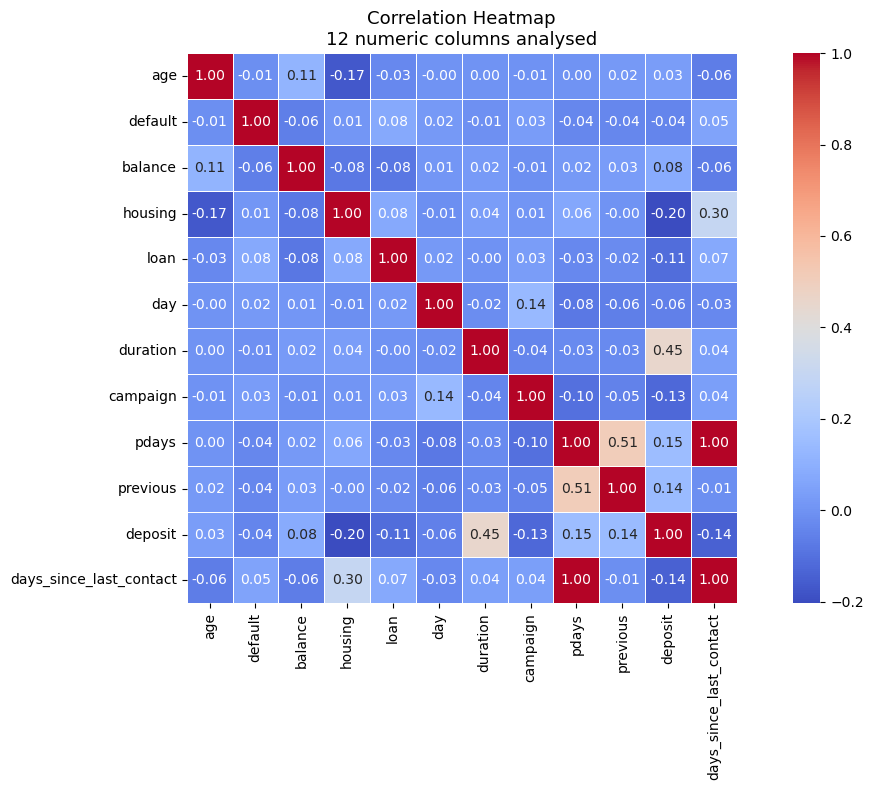

,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,deposit,days_since_last_contact
age,1.000000,-0.011425,0.112300,-0.168700,-0.031418,-0.000762,0.000189,-0.005278,0.002774,0.020169,0.034901,-0.062815
default,-0.011425,1.000000,-0.060954,0.011076,0.076434,0.017342,-0.009760,0.030975,-0.036282,-0.035273,-0.040680,0.054073
balance,0.112300,-0.060954,1.000000,-0.077092,-0.084589,0.010467,0.022436,-0.013894,0.017411,0.030805,0.081129,-0.062961
housing,-0.168700,0.011076,-0.077092,1.000000,0.076761,-0.014770,0.035051,0.006660,0.064497,-0.000840,-0.203888,0.296537
loan,-0.031418,0.076434,-0.084589,0.076761,1.000000,0.017269,-0.001914,0.034722,-0.030416,-0.022668,-0.110580,0.073814
day,-0.000762,0.017342,0.010467,-0.014770,0.017269,1.000000,-0.018511,0.137007,-0.077232,-0.058981,-0.056326,-0.032450
duration,0.000189,-0.009760,0.022436,0.035051,-0.001914,-0.018511,1.000000,-0.041557,-0.027392,-0.026716,0.451919,0.037588
campaign,-0.005278,0.030975,-0.013894,0.006660,0.034722,0.137007,-0.041557,1.000000,-0.102726,-0.049699,-0.128081,0.039973
pdays,0.002774,-0.036282,0.017411,0.064497,-0.030416,-0.077232,-0.027392,-0.102726,1.000000,0.507272,0.151593,1.000000
previous,0.020169,-0.035273,0.030805,-0.000840,-0.022668,-0.058981,-0.026716,-0.049699,0.507272,1.000000,0.139867,-0.012200


In [5]:
plot_correlation(bank, title='Correlation Heatmap', subtitle=None,
                     figsize=(12, 8), cmap='coolwarm')

**Feature Selection**

In [6]:
features = bank[['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'month', 'day', 'days_since_last_contact', 'previous', 'poutcome', 'was_previously_contacted','deposit']]

features

,age,job,marital,education,default,balance,housing,loan,contact,month,day,days_since_last_contact,previous,poutcome,was_previously_contacted,deposit
0,31,blue-collar,single,unknown,1,17,1,0,cellular,may,6,NaN,0,unknown,False,0
1,22,student,single,unknown,0,1,0,0,telephone,jun,15,NaN,0,unknown,False,0
2,21,student,single,unknown,0,200,0,0,unknown,jun,1,NaN,0,unknown,False,0
3,41,self-employed,single,unknown,0,426,1,0,unknown,jun,19,NaN,0,unknown,False,0
4,24,student,single,unknown,0,782,0,0,cellular,may,4,91.0,1,other,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,57,management,married,tertiary,0,473,0,0,cellular,jun,1,NaN,0,unknown,False,1
11158,39,technician,single,tertiary,0,861,0,0,unknown,jun,20,NaN,0,unknown,False,0
11159,29,management,single,tertiary,0,1566,1,0,unknown,jun,4,NaN,0,unknown,False,0
11160,35,management,married,tertiary,0,1193,1,0,unknown,jun,2,NaN,0,unknown,False,0


In [7]:
features.dtypes

age                           int64
job                          object
marital                      object
education                    object
default                       int64
balance                       int64
housing                       int64
loan                          int64
contact                      object
month                        object
day                           int64
days_since_last_contact     float64
previous                      int64
poutcome                     object
was_previously_contacted       bool
deposit                       int64
dtype: object

#### Preparing data for modeling

In [8]:
x=features.drop(columns=['deposit'])
#Target variable
y=features['deposit']

# Encode categorical columns one-hot encoding
x_encoded = pd.get_dummies(x, columns=['job', 'marital',     #then encode the categorical columns
                          'education', 'contact','month','poutcome'],
                          drop_first=True,
                          dtype=int)


print('===================Dependent Variables=================================')
display(x)
print('=====================Independent Variables=============================')
display(y)

===================Dependent Variables=================================


,age,job,marital,education,default,balance,housing,loan,contact,month,day,days_since_last_contact,previous,poutcome,was_previously_contacted
0,31,blue-collar,single,unknown,1,17,1,0,cellular,may,6,NaN,0,unknown,False
1,22,student,single,unknown,0,1,0,0,telephone,jun,15,NaN,0,unknown,False
2,21,student,single,unknown,0,200,0,0,unknown,jun,1,NaN,0,unknown,False
3,41,self-employed,single,unknown,0,426,1,0,unknown,jun,19,NaN,0,unknown,False
4,24,student,single,unknown,0,782,0,0,cellular,may,4,91.0,1,other,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,57,management,married,tertiary,0,473,0,0,cellular,jun,1,NaN,0,unknown,False
11158,39,technician,single,tertiary,0,861,0,0,unknown,jun,20,NaN,0,unknown,False
11159,29,management,single,tertiary,0,1566,1,0,unknown,jun,4,NaN,0,unknown,False
11160,35,management,married,tertiary,0,1193,1,0,unknown,jun,2,NaN,0,unknown,False


=====================Independent Variables=============================


0        0
1        0
2        0
3        0
4        0
        ..
11157    1
11158    0
11159    0
11160    0
11161    1
Name: deposit, Length: 11162, dtype: int64


**Train Test Split**    

splitting the data once into 2:   
                80% for training,     
                20% for testing(this is only used for final evaluation)    
> stratify = y ensures that **every model gets evaluated on the exact same customers**

In [9]:
#  Train/Test Split
# random_state=42 ensures same split every run
# 20% as final test set. never used for training or model selection

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)

print('Training set:', x_train.shape)
print('Test set:    ', x_test.shape)

Training set: (8929, 41)
Test set:     (2233, 41)


**Filling the NANs with the median of the non missing values**

> Median was used here instead of 0 because `was preciously contacted` tells the model whether   
the contact history is real and median filled `days since last contact` gives the model a    
number to work with for the never contacted rows that doesnt sit at a misleading extreme like a 0

In [11]:
#imputed version for logistic regression and random forest
imputed = SimpleImputer(strategy = 'median')
x_train_imputed = x_train.copy()
x_test_imputed = x_test.copy()

x_train_imputed['days_since_last_contact'] = imputed.fit_transform(x_train[['days_since_last_contact']])
x_test_imputed['days_since_last_contact'] = imputed.transform(x_test[['days_since_last_contact']])

# raw version for XGBoost(it handles NAN natively)
x_train_ui = x_train.copy()
x_test_ui = x_test.copy()


print('=================== X TRAIN IMPUTED =================================')
display(x_train_imputed)
print('===================== X TRAIN RAW =============================')
display(x_train_ui)


=================== X TRAIN IMPUTED =================================


,age,default,balance,housing,loan,day,days_since_last_contact,previous,was_previously_contacted,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
6401,28,0,1636,1,0,18,355.0,2,True,0,...,0,0,0,1,0,0,0,0,0,0
5448,49,0,320,0,0,9,182.0,0,False,0,...,0,0,0,0,0,0,0,0,0,1
6485,37,0,4017,0,0,16,182.0,0,False,0,...,0,0,0,0,0,1,0,0,0,1
2506,40,0,311,0,0,6,182.0,0,False,0,...,0,0,0,0,0,0,0,0,0,1
8750,31,0,354,0,0,21,182.0,0,False,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8251,26,0,3466,0,0,6,182.0,0,False,0,...,0,0,0,0,0,1,0,0,0,1
8048,49,0,234,0,0,22,182.0,0,False,0,...,0,0,0,0,0,0,0,0,0,1
7932,30,0,2325,0,0,10,127.0,7,True,0,...,0,0,0,0,0,0,0,0,0,0
7618,47,0,0,0,0,27,182.0,0,False,0,...,0,0,0,0,0,1,0,0,0,1


===================== X TRAIN RAW =============================


,age,default,balance,housing,loan,day,days_since_last_contact,previous,was_previously_contacted,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
6401,28,0,1636,1,0,18,355.0,2,True,0,...,0,0,0,1,0,0,0,0,0,0
5448,49,0,320,0,0,9,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
6485,37,0,4017,0,0,16,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1
2506,40,0,311,0,0,6,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
8750,31,0,354,0,0,21,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8251,26,0,3466,0,0,6,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1
8048,49,0,234,0,0,22,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
7932,30,0,2325,0,0,10,127.0,7,True,0,...,0,0,0,0,0,0,0,0,0,0
7618,47,0,0,0,0,27,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1


## LOGISTIC REGRESSION   
Standardizing dependent variables with StandardScaler because the Features are on completely different scales:

What StandardScaler Does  
 It rescales every feature so that:
* Mean = 0 (the average becomes zero)
* Standard deviation = 1 (the spread becomes 1)
* The formula: scaled_value = (original_value - mean) / std_deviation

The steps:
1. `fit()` on X_train → scaler learns the mean and std from training data
2. `transform()` on X_train → scales training data using those values
4. `transform()` on X_test → scales test data using the BEST values from validation
This way, the test data will be treated exactly like real unseen data would be.

In [12]:
# Create the scaler object
scaler = StandardScaler()

# Fit on training data ONLY 
x_train_imputed_scaled = scaler.fit_transform(x_train_imputed)

#transforming the test data
x_test_imputed_scaled = scaler.transform(x_test_imputed)

# Putting them back into a DataFrame so we can see column names
x_train_imputed_scaled_df = pd.DataFrame(x_train_imputed_scaled, columns=x_train_imputed.columns)
x_train_imputed_scaled_df.head()

,age,default,balance,housing,loan,day,days_since_last_contact,previous,was_previously_contacted,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,-1.109140,-0.125291,0.027049,1.058727,-0.387747,0.278334,2.627743,0.536155,1.713753,-0.460999,...,-0.397815,-0.349912,-0.160045,1.717814,-0.297497,-0.191543,-0.174208,-0.221614,-0.328563,-1.714766
1,0.647143,-0.125291,-0.371331,-0.944531,-0.387747,-0.793406,-0.095665,-0.377806,-0.583515,-0.460999,...,-0.397815,-0.349912,-0.160045,-0.582135,-0.297497,-0.191543,-0.174208,-0.221614,-0.328563,0.583170
2,-0.356447,-0.125291,0.747825,-0.944531,-0.387747,0.040170,-0.095665,-0.377806,-0.583515,-0.460999,...,-0.397815,-0.349912,-0.160045,-0.582135,-0.297497,5.220759,-0.174208,-0.221614,-0.328563,0.583170
3,-0.105550,-0.125291,-0.374055,-0.944531,-0.387747,-1.150653,-0.095665,-0.377806,-0.583515,-0.460999,...,-0.397815,-0.349912,-0.160045,-0.582135,-0.297497,-0.191543,-0.174208,-0.221614,-0.328563,0.583170
4,-0.858243,-0.125291,-0.361038,-0.944531,-0.387747,0.635581,-0.095665,-0.377806,-0.583515,-0.460999,...,-0.397815,-0.349912,-0.160045,-0.582135,-0.297497,-0.191543,-0.174208,-0.221614,-0.328563,0.583170


#### INTRODUCING THE MODEL TO THE DATASET USING THE TRAINING SET
Here the model learn the relationship between the dependent and independent variables

In [13]:
# MODEL1: Logistic Regression on standardised data
# Features: all features (scaled) | Data: X_train_scaled, y_train

LR = LogisticRegression()
LR.fit(x_train_imputed_scaled_df, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul


##### Model Parameters from the learning
Intercept and Coefficients

In [14]:
# Raw coefficients 
coef_df = pd.DataFrame(LR.coef_.T,
    index=x_train_imputed_scaled_df.columns, columns=['Log Odds Coefficient'])

print('Raw Log Odds Coefficients:')
print(coef_df)

Raw Log Odds Coefficients:
                          Log Odds Coefficient
age                                   0.012303
default                              -0.017502
balance                               0.130029
housing                              -0.193358
loan                                 -0.124911
day                                  -0.059975
days_since_last_contact              -0.005034
previous                              0.020930
was_previously_contacted              0.012075
job_blue-collar                       0.009751
job_entrepreneur                     -0.022707
job_housemaid                        -0.047587
job_management                       -0.045172
job_retired                           0.123685
job_self-employed                     0.005485
job_services                         -0.022474
job_student                           0.114249
job_technician                        0.013985
job_unemployed                        0.044077
job_unknown                      


###### Model Parameters: Intercept and Coefficients
* The coefficients are in LOG ODDS, not plain numbers.
* Odds = probability of event happening / probability of event NOT happening
* Log Odds = log(odds) This is hard to interpret directly.
* so convert log odds to Odds Ratios using np.exp() (the exponential function).


In [15]:
odds_df = pd.DataFrame(
    np.exp(LR.coef_),
    columns=x_train_imputed_scaled_df.columns).T

#putting them in a dataframe
odds_df.columns = ['Odds Ratio']
odds_df = odds_df.sort_values('Odds Ratio', ascending=False)

print('Odds Ratios (sorted from highest to lowest):')
print(odds_df.round(3))

Odds Ratios (sorted from highest to lowest):
                          Odds Ratio
poutcome_success               1.864
month_mar                      1.271
month_dec                      1.177
education_tertiary             1.167
month_oct                      1.162
balance                        1.139
job_retired                    1.132
job_student                    1.121
month_sep                      1.101
poutcome_other                 1.049
education_secondary            1.047
job_unemployed                 1.045
marital_single                 1.044
previous                       1.021
job_technician                 1.014
poutcome_unknown               1.013
age                            1.012
was_previously_contacted       1.012
education_unknown              1.010
job_blue-collar                1.010
job_self-employed              1.005
days_since_last_contact        0.995
job_unknown                    0.991
default                        0.983
job_services                  

#### Interpretation of the Odds Ratios
* Odds ratio > 1 → higher value of this feature → MORE likely to subscribe 
* Odds ratio < 1 → higher value of this feature → LESS likely to subscribe 
* Odds ratio ≈ 1 → this feature has little to no effect on the prediction  

#### The Percentage Interpretation Using the above Results
Using the % formula: (odds ratio - 1) × 100

 **poutcome_success  - Odds Ratio: 1.864**  
`1.864 → (1.864 - 1) × 100 = 86.4%`  
→ A 1 unit increase in poutcome_success multiplies the odds of a customer subscribing by 1.864  
→ i.e., 86% increase in odds of a customer saying yes  
→ The single strongest predictor in this model  

In [16]:
# Splitting into two groups to make interpretation easier

print(' FEATURES THAT INCREASE ODDS OF A CUSTOMER CHOOSING DEPOSIT (Odds Ratio > 1) ')
print(odds_df[odds_df['Odds Ratio'] > 1].round(3))
print()
print(' FEATURES THAT DECREASE ODDS OF BEING DEPOSIT (Odds Ratio < 1) ')
print(odds_df[odds_df['Odds Ratio'] < 1].sort_values('Odds Ratio').round(3))

 FEATURES THAT INCREASE ODDS OF A CUSTOMER CHOOSING DEPOSIT (Odds Ratio > 1) 
                          Odds Ratio
poutcome_success               1.864
month_mar                      1.271
month_dec                      1.177
education_tertiary             1.167
month_oct                      1.162
balance                        1.139
job_retired                    1.132
job_student                    1.121
month_sep                      1.101
poutcome_other                 1.049
education_secondary            1.047
job_unemployed                 1.045
marital_single                 1.044
previous                       1.021
job_technician                 1.014
poutcome_unknown               1.013
age                            1.012
was_previously_contacted       1.012
education_unknown              1.010
job_blue-collar                1.010
job_self-employed              1.005

 FEATURES THAT DECREASE ODDS OF BEING DEPOSIT (Odds Ratio < 1) 
                         Odds Ratio
contact

---
#### PREDICTING ON THE TEST SET WITH THE MODEL EXPOSED TO TRAINING SET
Predicting on the Test data

In [17]:
x_test_imputed_scaled_df = pd.DataFrame(x_test_imputed_scaled, columns=x_test_imputed.columns)

# Predict on scaled test data
y_test_pred = LR.predict(x_test_imputed_scaled_df)

# Evaluate
print(' TEST DATA EVALUATION ')
print(metrics.classification_report(y_test, y_test_pred, target_names=['Unsubscribed', 'Subscribed']))

y_test_prob = LR.predict_proba(x_test_imputed_scaled_df)[:,1]
roc_auc = roc_auc_score(y_test, y_test_prob)
print(f'ROC-AUC SCORE:{roc_auc:.4f}')

 TEST DATA EVALUATION 
              precision    recall  f1-score   support

Unsubscribed       0.67      0.82      0.74      1175
  Subscribed       0.74      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.71      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233

ROC-AUC SCORE:0.7540


In [18]:
print('ACCURACY')
print(LR.score(x_train_imputed_scaled_df, y_train))
print(LR.score(x_test_imputed_scaled_df, y_test))

ACCURACY
0.7063500951954306
0.6972682489923869


#### Model Evaluation

**Accuracy - 0.706 (71%)**  
71% of all predictions made by the model were correct.

**Precision (Subscribed) - 0.74 (74%)**  
When the model predicts a customer will "Subscribe", it is correct 74% of the time.  

**Recall / Sensitivity (Subscried) - 0.56 (56%)**  
Out of all customers, the model successfully predicted 56% will subscribe

**ROC-AUC Score - 0.7540**  
The model has a 75.40% ability to distinguish between customers who will subscribe and those that won't.

**Conclusion**    
The report shows an f1-score of 64% for customers who are likely to subscribe compared to 74% for unsubscribed  

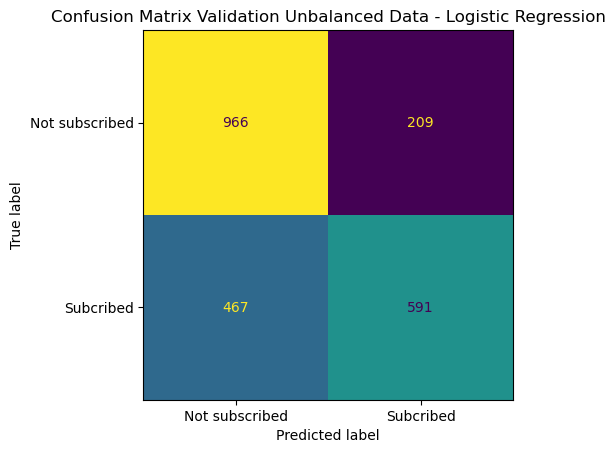

In [67]:
# Confusion Matrix for validation data
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=['Not subscribed', 'Subcribed'],
                                       colorbar=False)
plt.title('Confusion Matrix Validation Unbalanced Data - Logistic Regression')
plt.show()

| | Predicted: Not subscribed | Predicted: Subscribed |
|---|---|---|
| **Actual: Non Subscribed**   | **True Negative** ✅  | **False Positive** ⚠️ |
| **Actual: Subscribed**       | **False Negative** ❌ | **True Positive** ✅  |

**What each outcome means:**
- `966` **True Negative** — Model said not subscribed, they did not subscribe.(✅ Customers correctly identified as likely to subscribe)
- `209`  **False Positive** — Model said will subscribe, but they did not.(⚠️ Customers wrongly flagged as will subscribe )
- `467`  **False Negative** — Model said not subscribed, but they did. Customers missed.(❌ likely to subscribe Customers missed)
- `591` **True Positive** — Model correctly predicted them as will subscribe( ✅ will subscribe customers correctly identified )


model 2   
## Random Forest

In [20]:
print('INDEPENDENT VARIABLES')
print(x_train_imputed)
print('TARGET VARIABLES')
print(y_train)

INDEPENDENT VARIABLES
      age  default  balance  housing  loan  day  days_since_last_contact  \
6401   28        0     1636        1     0   18                    355.0   
5448   49        0      320        0     0    9                    182.0   
6485   37        0     4017        0     0   16                    182.0   
2506   40        0      311        0     0    6                    182.0   
8750   31        0      354        0     0   21                    182.0   
...   ...      ...      ...      ...   ...  ...                      ...   
8251   26        0     3466        0     0    6                    182.0   
8048   49        0      234        0     0   22                    182.0   
7932   30        0     2325        0     0   10                    127.0   
7618   47        0        0        0     0   27                    182.0   
8159   52        0     -803        1     0    7                    182.0   

      previous  was_previously_contacted  job_blue-collar  ...  m

#### Confirm Class Balance

In [21]:
from collections import Counter

print(Counter(y))
print('Y Train')
print(Counter(y_train))
print('Y Test')
print(Counter(y_test))

Counter({0: 5873, 1: 5289})
Y Train
Counter({0: 4698, 1: 4231})
Y Test
Counter({0: 1175, 1: 1058})


**CROSS VALIDATION**   
Checking the reliability and consistency of the model

In [22]:
RF = RandomForestClassifier(random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

RF_scores = cross_validate(RF, x_train_imputed, y_train, cv = cv,
    scoring = ["accuracy", "precision", "recall", "f1", "precision_weighted", "f1_weighted"]
)

RF_scores

{'fit_time': array([14.74670339, 10.76043367,  9.02042913,  8.30423188,  8.09227872]),
 'score_time': array([0.64489317, 0.49638653, 0.54619002, 0.45376062, 0.37154508]),
 'test_accuracy': array([0.69260918, 0.72396417, 0.73460246, 0.73628219, 0.73053221]),
 'test_precision': array([0.70539419, 0.7394844 , 0.75135135, 0.75201072, 0.74236388]),
 'test_recall': array([0.60283688, 0.64420804, 0.6572104 , 0.66233766, 0.6607565 ]),
 'test_f1': array([0.6500956 , 0.68856601, 0.70113493, 0.70433145, 0.69918699]),
 'test_precision_weighted': array([0.69408854, 0.72557685, 0.73629977, 0.73780968, 0.73159844]),
 'test_f1_weighted': array([0.68999851, 0.7220243 , 0.73281618, 0.73465156, 0.72905321])}

In [23]:
print("Mean accuracy:",           RF_scores['test_accuracy'].mean())
print("Mean precision:",          RF_scores['test_precision'].mean())
print("Mean recall:",             RF_scores['test_recall'].mean())
print("Mean f1:",                 RF_scores['test_f1'].mean())
print("Mean precision weighted:", RF_scores['test_precision_weighted'].mean())
print("Mean f1 weighted:",        RF_scores['test_f1_weighted'].mean())

Mean accuracy: 0.7235980439208158
Mean precision: 0.738120908021234
Mean recall: 0.6454698965337263
Mean f1: 0.6886629977598652
Mean precision weighted: 0.7250746547155156
Mean f1 weighted: 0.7217087532239582


In [24]:
#Train on training set
RF.fit(x_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [68]:
#predict on test set
y_test_pred_RF = RF.predict(x_test_imputed)

#evaluate test results
print('=============== RANDOM FOREST CLASSIFICATION REPORT===========')
print(classification_report(y_test, y_test_pred_RF,
                                  target_names=['Not subscribed', 'Subscribed']))

y_test_prob_RF = RF.predict_proba(x_test_imputed)[:,1]
roc_auc = roc_auc_score(y_test, y_test_prob_RF)
print(f'ROC-AUC SCORE:{roc_auc:.4f}')

=============== RANDOM FOREST CLASSIFICATION REPORT===========
                precision    recall  f1-score   support

Not subscribed       0.70      0.80      0.75      1175
    Subscribed       0.74      0.63      0.68      1058

      accuracy                           0.72      2233
     macro avg       0.72      0.71      0.71      2233
  weighted avg       0.72      0.72      0.71      2233

ROC-AUC SCORE:0.7619


In [26]:
#check feature importance
feature_performance = pd.Series(RF.feature_importances_,
                               index=x_train_imputed.columns).sort_values(ascending=False)
feature_performance

balance                     0.183569
age                         0.159126
day                         0.139716
poutcome_success            0.039600
days_since_last_contact     0.038302
contact_unknown             0.037451
housing                     0.026715
previous                    0.025719
education_secondary         0.019899
loan                        0.019169
marital_married             0.018182
month_may                   0.016300
education_tertiary          0.015932
job_technician              0.015670
job_blue-collar             0.015106
month_aug                   0.014564
marital_single              0.014552
job_management              0.014424
month_jul                   0.012994
month_nov                   0.012174
poutcome_unknown            0.011999
month_jun                   0.011897
month_mar                   0.011869
contact_telephone           0.011290
month_oct                   0.010798
job_services                0.010471
was_previously_contacted    0.010337
m

The default recall of **63%** is low    
Before accepting this, hyperparameter tuning will be applied using RandomizedSearchCV which samples a fixed number of combinations(n_iter = 20 above) to find the best combination of model settings

**What will be tuned**  
- max_depth: how deep each tree grows before making a decision
- n_estimators: how many trees are built and voted on

The process will pick scoring = 'roc_auc' over plain accuracy for the tuning metric because it measures how well the model ranks 'likely yes' customers above 'likely no' customers because the bank will prefer a `call the top ranked prospects first` than a `did it get the label right`

In [29]:
# Applying hyperparameter tuning with RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

rf_tuned = RandomizedSearchCV(
    RandomForestClassifier(random_state = 42),
    param_distributions = {
        'n_estimators':[100, 200, 300, 500],
        "max_depth": [5, 10,15, 20, None],
        "min_samples_leaf": [1, 2, 5, 10],
},
n_iter = 20, cv = 5, scoring ='roc_auc', random_state = 42, n_jobs = -1)

rf_tuned.fit(x_train_imputed, y_train)
print('Best Parameters:', rf_tuned.best_params_)

Best Parameters: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_depth': 20}


In [30]:
rf_tuned.best_estimator_

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [31]:
# using the output from therandomized search to retrain on training set
RF_tuned = RandomForestClassifier(
    max_depth    = 20,
    n_estimators = 500,
    random_state = 42,
    min_samples_leaf = 2
)

RF_tuned.fit(x_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [32]:
#Evaluating on test set
y_test_pred_RF2  = RF_tuned.predict(x_test_imputed)
y_test_prob_RF2 = RF_tuned.predict_proba(x_test_imputed)[:,1]
roc_auc = roc_auc_score(y_test, y_test_prob_RF2)

print(classification_report(y_test, y_test_pred_RF2))
print(f'ROC-AUC SCORE:{roc_auc:.4f}')

              precision    recall  f1-score   support

           0       0.70      0.83      0.76      1175
           1       0.76      0.60      0.67      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.71      0.71      2233
weighted avg       0.73      0.72      0.72      2233

ROC-AUC SCORE:0.7819


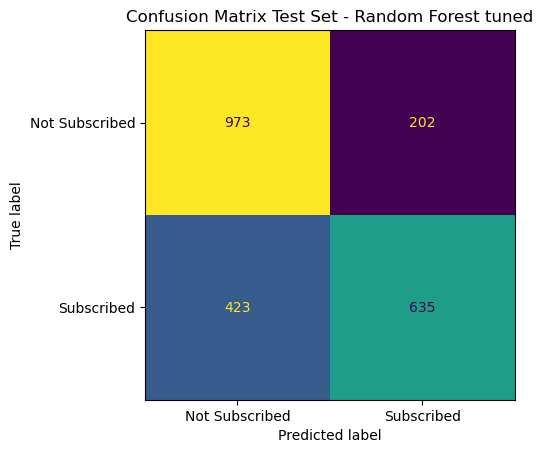

In [33]:
# Confusion Matrix for validation data

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_RF2, display_labels=['Not Subscribed', 'Subscribed'],
                                       colorbar=False)
plt.title('Confusion Matrix Test Set - Random Forest tuned')
plt.show()

| | Predicted: Non subscribed | Predicted: Subscribed |
|---|---|---|
| **Actual: Non Subscribed**   | **True Negative** ✅  | **False Positive** ⚠️ |
| **Actual: Subscribed**       | **False Negative** ❌ | **True Positive** ✅  |

**What each outcome means:**
- `973` **True Negative** — Model said not subscribed, they did not subscribe.(✅ Customers correctly identified as likely to subscribe)
- `423`  **False Positive** — Model said will subscribe, but they did not.(⚠️ Customers wrongly flagged as will subscribe )
- `202`  **False Negative** — Model said not subscribed, but they did. Customers missed.(❌ likely to subscribe Customers missed)
- `635` **True Positive** — Model correctly predicted them as will subscribe( ✅ will subscribe customers correctly identified )


---
**Model 3**

## XGBOOST

**What it is:** Its an Extreme Gradient Boosting that builds trees sequentially(RF builds them in parallel)
Each new tree learns from the errors of the previous one, gradually improving predictions.

**Why use it:** XGBoost is generally the strongest performer on 
structured tabular data. It handles missing values, learns 
complex patterns, and is more efficient than Random Forest 
on large feature sets.

**Key parameters used:**
- `n_estimators=500` - number of trees to build
- `learning_rate=0.1` - how much each tree corrects the 
  previous one. Lower = slower but more precise learning
- `max_depth=6` - how deep each tree grows before stopping. 
  Controls complexity and overfitting risk.
- `random_state=42` - ensures reproducible results

**No scaling needed** 

---
**Cross Validation**

In [34]:
display(x_train_ui)

,age,default,balance,housing,loan,day,days_since_last_contact,previous,was_previously_contacted,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
6401,28,0,1636,1,0,18,355.0,2,True,0,...,0,0,0,1,0,0,0,0,0,0
5448,49,0,320,0,0,9,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
6485,37,0,4017,0,0,16,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1
2506,40,0,311,0,0,6,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
8750,31,0,354,0,0,21,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8251,26,0,3466,0,0,6,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1
8048,49,0,234,0,0,22,NaN,0,False,0,...,0,0,0,0,0,0,0,0,0,1
7932,30,0,2325,0,0,10,127.0,7,True,0,...,0,0,0,0,0,0,0,0,0,0
7618,47,0,0,0,0,27,NaN,0,False,0,...,0,0,0,0,0,1,0,0,0,1


In [35]:
# XGBoost: 5-Fold CV 

XGB = XGBClassifier(n_estimators=100,
                    learning_rate=0.1,
                    max_depth=5,
                    random_state=42,
                    eval_metric='logloss')
#Fit on training set
XGB.fit(x_train_ui, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [51]:
#Evaluate on test
y_test_pred_XGB = XGB.predict(x_test_ui)
y_test_prob_XGB = XGB.predict_proba(x_test_ui)[:, 1]


roc_auc_XGB = roc_auc_score(y_test, y_test_prob_XGB)
print(classification_report(y_test, y_test_pred_XGB))
print(f'ROC-AUC Score: {roc_auc_XGB:.4f}')

              precision    recall  f1-score   support

           0       0.69      0.84      0.76      1175
           1       0.77      0.59      0.67      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.71      0.71      2233
weighted avg       0.73      0.72      0.72      2233

ROC-AUC Score: 0.7853


**Applying hyperparameter tuning with RandomizedSearchCV**

In [37]:
XGB_tuned = RandomizedSearchCV(
    XGBClassifier(random_state = 42),
    param_distributions = {
        'n_estimators':[100, 200, 300, 500],
        "max_depth": [5, 10,15, 20, None],
        "min_samples_leaf": [1, 2, 5, 10],
},
n_iter = 20, 
cv = 5, 
scoring ='roc_auc', 
random_state = 42, 
n_jobs = -1)


#Fit on training set
XGB_tuned.fit(x_train_ui, y_train)

print('Best Parameters:', XGB_tuned.best_params_)

Best Parameters: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 5}


In [38]:
XGB_tuned.best_estimator_

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [39]:
# using the output from the search to retrain on training set
XGB_tuned = XGBClassifier(
    max_depth    = 5,
    n_estimators = 100,
    min_samples_leaf = 1,
    random_state = 42
)

XGB_tuned.fit(x_train_ui, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [40]:
#Evaluate on test
y_test_pred_XGB2 = XGB_tuned.predict(x_test_ui)
y_test_prob_XGB2 = XGB_tuned.predict_proba(x_test_ui)[:, 1]
roc_auc = roc_auc_score(y_test, y_test_prob_XGB2)

print('============= XG BOOST TUNED CLASSIFICATION REPORT ======')
print(classification_report(y_test, y_test_pred_XGB2))
print(f'ROC-AUC Score: {roc_auc:.4f}')

============= XG BOOST TUNED CLASSIFICATION REPORT ======
              precision    recall  f1-score   support

           0       0.70      0.81      0.75      1175
           1       0.74      0.61      0.67      1058

    accuracy                           0.71      2233
   macro avg       0.72      0.71      0.71      2233
weighted avg       0.72      0.71      0.71      2233

ROC-AUC Score: 0.7715


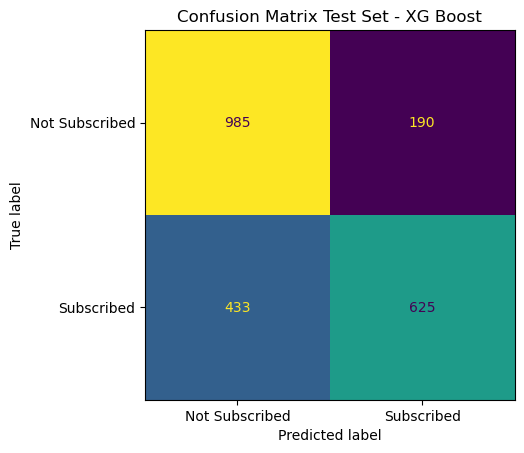

In [45]:
# Confusion Matrix for validation data

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_XGB, display_labels=['Not Subscribed', 'Subscribed'],
                                       colorbar=False)
plt.title('Confusion Matrix Test Set - XG Boost')
plt.show()

| | Predicted: Non subscribed | Predicted: Subscribed |
|---|---|---|
| **Actual: Non Subscribed**   | **True Negative** ✅  | **False Positive** ⚠️ |
| **Actual: Subscribed**       | **False Negative** ❌ | **True Positive** ✅  |

**What each outcome means:**
- `985` **True Negative** — Model said not subscribed, they did not subscribe.(✅ Customers correctly identified as likely to subscribe)
- `433`  **False Positive** — Model said will subscribe, but they did not.(⚠️ Customers wrongly flagged as will subscribe )
- `190`  **False Negative** — Model said not subscribed, but they did. Customers missed.(❌ likely to subscribe Customers missed)
- `625` **True Positive** — Model correctly predicted them as will subscribe( ✅ will subscribe customers correctly identified )


**Print Feature Importance/SHAP Values on the selected model**   

**`XG Boost Default`**

In [41]:
#check feature importance
feature_performance_XGB = pd.Series(XGB.feature_importances_,
                              index=x_train_ui.columns).sort_values(ascending=False)
feature_performance_XGB

poutcome_success            0.377310
month_mar                   0.089582
contact_unknown             0.068095
month_jun                   0.042207
month_oct                   0.035797
month_aug                   0.026440
housing                     0.026202
month_jul                   0.021759
month_dec                   0.018704
month_nov                   0.017586
month_sep                   0.015795
job_student                 0.014027
loan                        0.013848
month_feb                   0.013511
month_jan                   0.013214
day                         0.012121
marital_married             0.012033
education_tertiary          0.011368
education_unknown           0.010905
days_since_last_contact     0.010772
age                         0.010718
month_may                   0.010087
balance                     0.009148
job_management              0.009119
job_blue-collar             0.008992
job_services                0.008929
contact_telephone           0.008559
j

In [42]:
#check feature importance
feature_performance_XGB_df = feature_performance_XGB.to_frame(name='values').round(2).reset_index(names='features')
feature_performance_XGB_df

,features,values
0,poutcome_success,0.38
1,month_mar,0.09
2,contact_unknown,0.07
3,month_jun,0.04
4,month_oct,0.04
5,month_aug,0.03
6,housing,0.03
7,month_jul,0.02
8,month_dec,0.02
9,month_nov,0.02


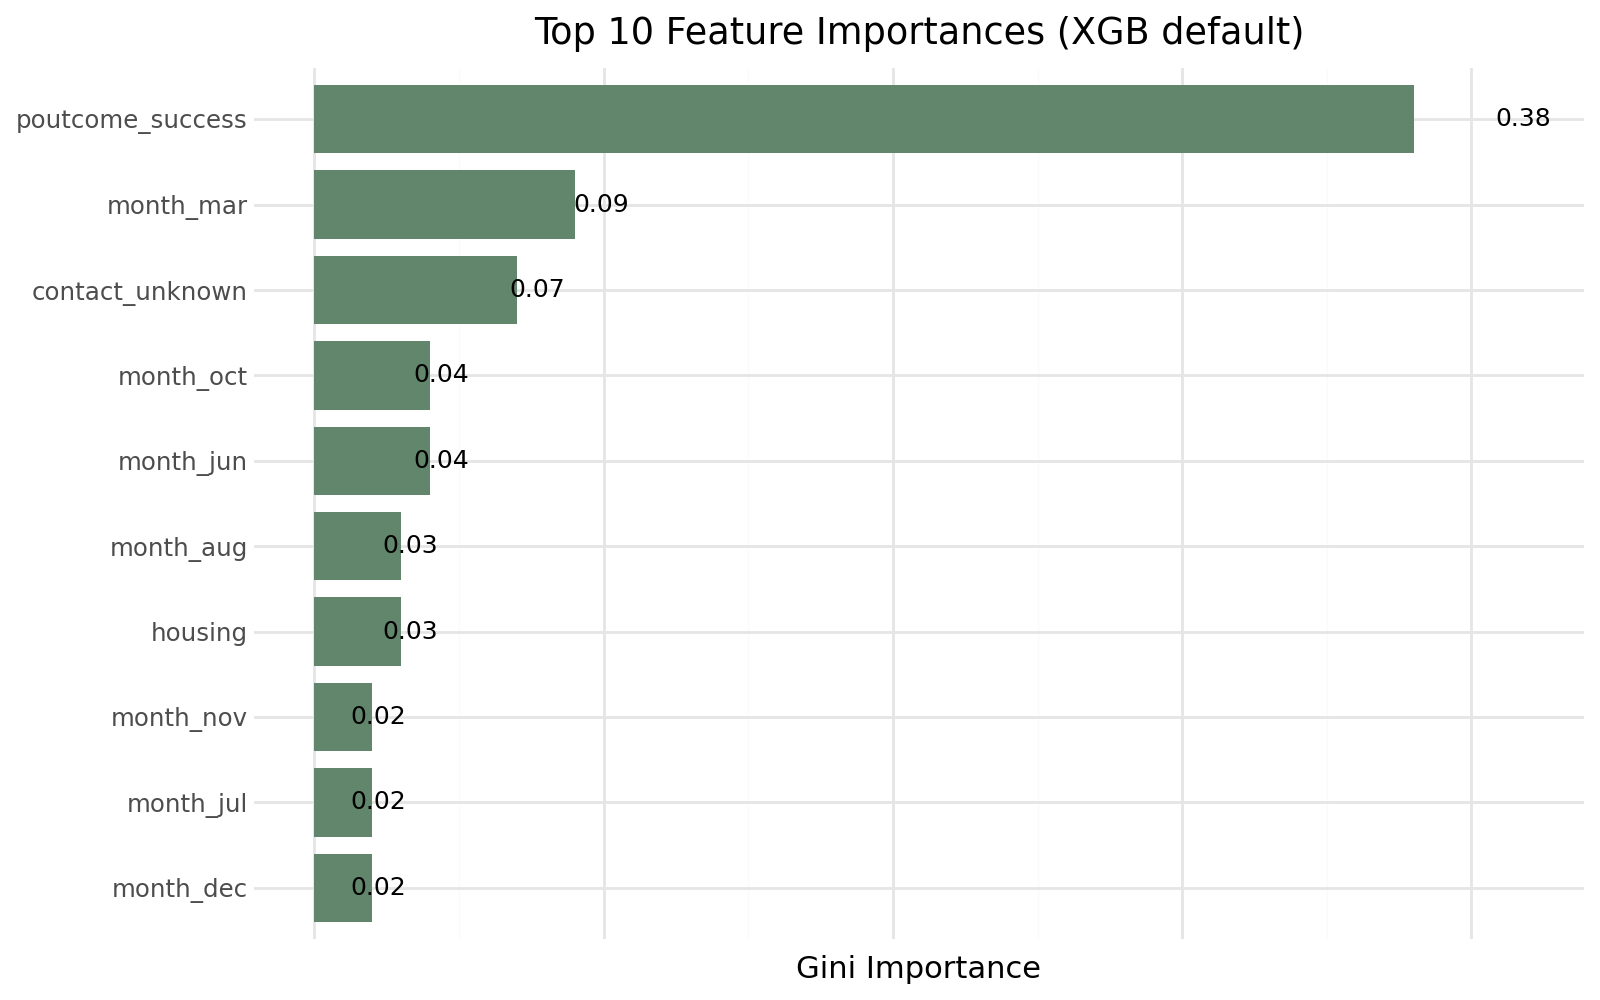

In [66]:
top_10 = feature_performance_XGB_df.sort_values(by='values', ascending=False).head(10).copy()

# Add a pre-formatted string column 
top_10['label_text'] = top_10['values'].round(2).astype(str)

chart = (ggplot(top_10, aes(x='reorder(features, values)', y='values'))
 + geom_col(width=0.8, show_legend=False, fill='#62866C')
 + coord_flip()
 + geom_text(aes(label='label_text'), position=position_stack(vjust=1.1), size=9)
 + theme_minimal()
 + labs(title='Top 10 Feature Importances (XGB default)',
        x='',
        y='Gini Importance')
 + theme(figure_size=(8, 5),
        axis_text_x=element_blank(),
        axis_line_y=element_blank())
)
chart

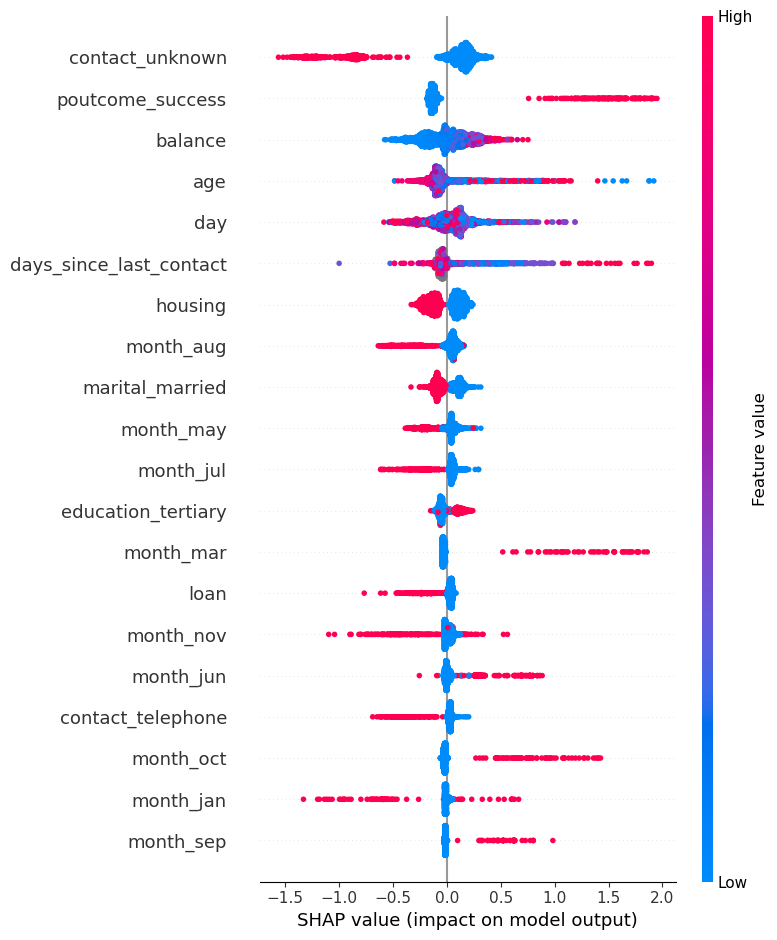

In [52]:
import shap

# Create a TreeExplainer for XGBoost model
explainer = shap.TreeExplainer(XGB)

# Calculate SHAP values on test dataset
shap_values = explainer(x_test)

# Generate the SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, x_test)

In [56]:
# Compute mean absolute SHAP value per feature
mean_shap = np.abs(shap_values.values).mean(axis=0)

# Create a styled DataFrame
shap_df = pd.DataFrame({
    'Feature': x_test.columns,
    'Mean_SHAP_Impact': mean_shap
}).sort_values(by='Mean_SHAP_Impact', ascending=False).reset_index(drop=True).round(2)

print(shap_df.head(10))

                   Feature  Mean_SHAP_Impact
0          contact_unknown              0.33
1         poutcome_success              0.25
2                  balance              0.16
3                      age              0.16
4                      day              0.15
5  days_since_last_contact              0.13
6                  housing              0.13
7                month_aug              0.10
8          marital_married              0.09
9                month_may              0.09


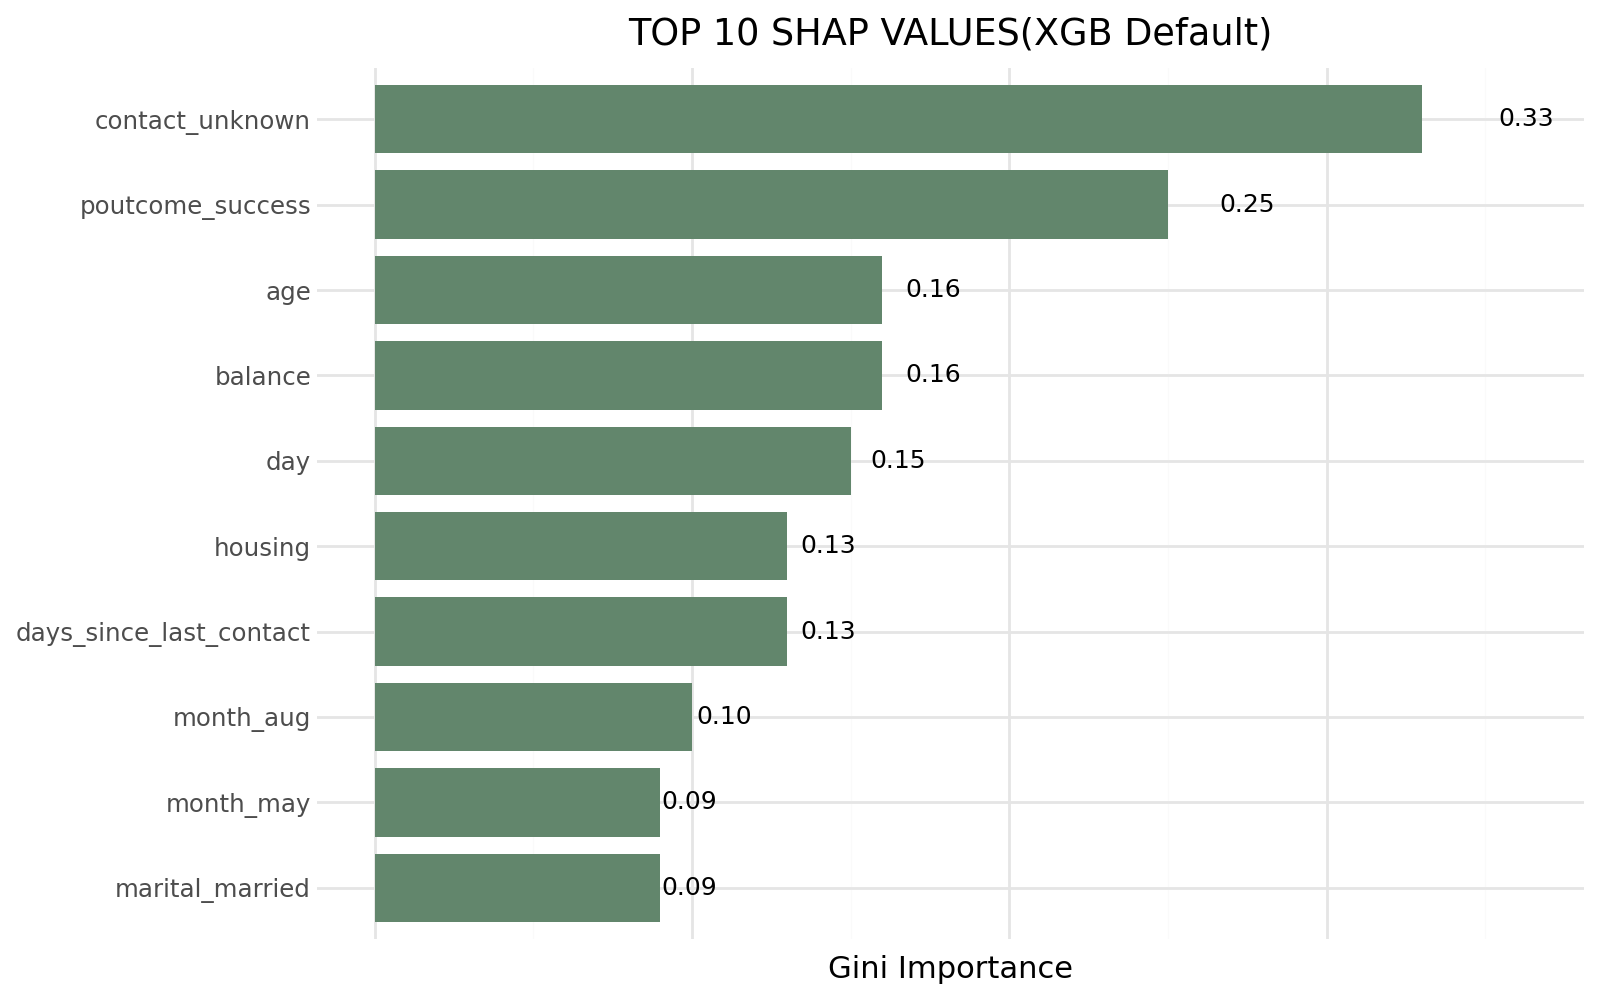

In [61]:
top_10 = shap_df.round(2).sort_values(by='Mean_SHAP_Impact', ascending=False).head(10).round(2)

chart = (ggplot(top_10, aes(x='reorder(Feature,Mean_SHAP_Impact)', y='Mean_SHAP_Impact'))
+ geom_col(width=0.8, show_legend=False, fill='#62866C')
+ coord_flip()
+ geom_text(aes(label='[f"{x:.2f}" for x in Mean_SHAP_Impact]'), position=position_stack(vjust=1.1), size=9)
+ theme_minimal()
+ labs(title='TOP 10 SHAP VALUES(XGB Default)',
       x='',
       y='Gini Importance')
+ theme(figure_size=(8, 5),
        axis_text_x=element_blank(),
        axis_line_y=element_blank())
)
chart

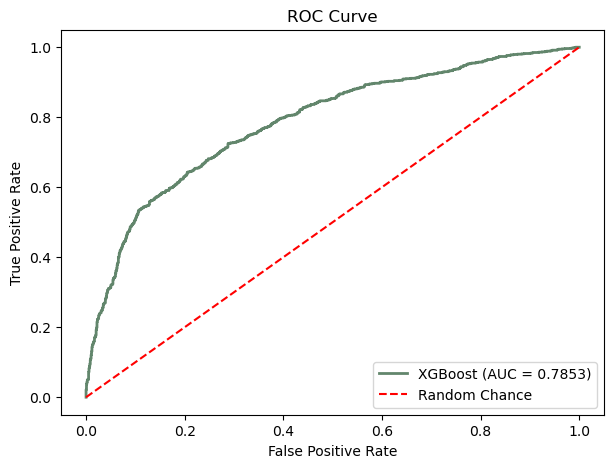

In [74]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

# Plot Confusion Matrix
#ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_XGB, cmap='Greens')
#plt.title('Confusion Matrix - Default XGBoost')
#plt.show()

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_prob_XGB)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#62866C', lw=2, label=f'XGBoost (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

The XGBoost classifier achieved an ROC-AUC score of 0.7853, demonstrating solid predictive performance. The model significantly outperforms random chance ($0.50$), effectively ranking high-probability leads above non-converting contacts. This confirms that the underlying features successfully capture customer conversion dynamics to support targeted campaign outreach.

---
## Model Comparison Summary

| Model | Recall  | Precision | F1  | Accuracy | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.56 | 0.74 | 0.64 | 0.70 | 0.75 |
| Random Forest (default) | 0.63 | 0.74 | 0.68 | 0.72 | 0.76 |
| Random Forest (tuned) | 0.60 | 0.76 | 0.67 | 0.72 | 0.78 |
| XGBoost(default) | 0.59 | 0.77 | 0.67 | 0.72 |**0.785** |    
| XGBoost(tuned) | 0.61 | 0.74 | 0.67 | 0.71 |0.77 |  

---
## Conclusion

> **Selected Model: XG Boost default**

Chosen for the best ROC-AUC of all five models (0.7853), narrowly ahead of Random Forest (tuned) at 0.7819.   
The untuned, default XGBoost model outperforms every tuned model in the comparison. This reinforces a finding; for this dataset, algorithm choice mattered more than hyperparameter tuning, and tuning produced small, inconsistent gains rather than a clear, reliable improvement. 

All five models converged within a fairly tight performance band (accuracy 0.70-0.72, ROC-AUC 0.75-0.79). This suggests the available features carry a real but limited amount of predictive signal, consistent with the strongest EDA finding (poutcome_success) already capturing much of the available signal on its own.


